Step 1: Generate Simple Data
Data shape: (500, 2)


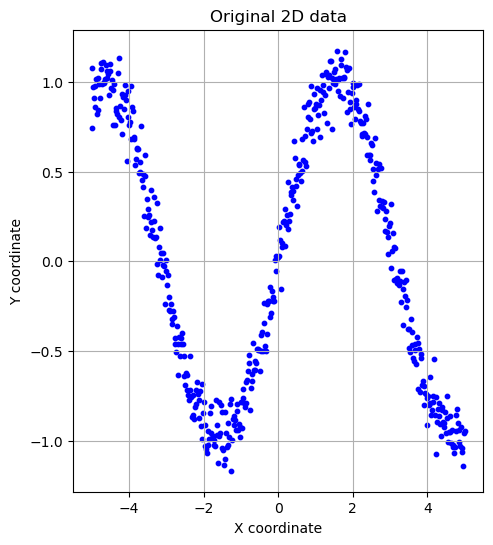

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

# ---- 1. Generate simple 2D data
print("Step 1: Generate Simple Data")
np.random.seed(63)
num_samples = 500

# Generate x values and Noise to make more realistic
X_base = np.linspace(-5, 5, num_samples)
noise = np.random.normal(0, 0.1, num_samples)

# 2D-Data will be (x, sin(x) + noise)
original_data = np.array([X_base, np.sin(X_base) + noise]).T
print(f"Data shape: {original_data.shape}")

# Plot 1 : Original Data
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.scatter(original_data[:, 0], original_data[:, 1], c='blue', s=10)
plt.title('Original 2D data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True)

In [3]:
# --- 2. Define Deeper AUtoencoder Architecture ---
# Add of intermediate hidden layer to both encoder and decoder
print("\nStep2: Building a deeper autoencoder model: ")


# Define the dimensions
input_dim = 2
encoding_dim = 1  # Could still use 1D bottleNeck
intermediate_dim = 16 #More Neurons to learn complex patterns

# Input layer
input_layer =Input(shape=(input_dim,), name='Input')

# Encoder: Add a hidden layer for more capacity
encoder_hidden = Dense(intermediate_dim, activation='relu', name='Encoder_hidden')(input_layer)
encoder_output = Dense(encoding_dim, activation='relu', name='Encoder-output')(encoder_hidden)  

# Decoder: Mirror the Encoder's Structure
decoder_hidden = Dense(intermediate_dim, activation='relu', name='Decoder_hidden')(encoder_output)
decoder_output = Dense(input_dim, activation=None, name='Decoder_output')(decoder_hidden)  # Final Layer can be linear

# Autoencoder model: Maps an input to its reconstruction
autoencoder = Model(inputs=input_layer, outputs=decoder_output, name='Autoencoder')

# Possible: To create separatye model just for encoder
encoder = Model(inputs=input_layer, outputs=encoder_output, name='Encoder_Model')

# Compile the Autoencoder model
autoencoder.compile(optimizer=Adam(learning_rate=0.0005), loss='mean_square_error')
autoencoder.summary()


Step2: Building a deeper autoencoder model: 
Model: "Autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Input (InputLayer)          [(None, 2)]               0         
                                                                 
 Encoder_hidden (Dense)      (None, 16)                48        
                                                                 
 Encoder-output (Dense)      (None, 1)                 17        
                                                                 
 Decoder_hidden (Dense)      (None, 16)                32        
                                                                 
 Decoder_output (Dense)      (None, 2)                 34        
                                                                 
Total params: 131
Trainable params: 131
Non-trainable params: 0
_________________________________________________________________


In [1]:
import tensorflow as tf; 
print(tf.config.list_physical_devices('GPU'))


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Step 1: Generate Simple Data
Data shape: (500, 2)

Step2: Building a deeper autoencoder model: 
Model: "Autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Input (InputLayer)          [(None, 2)]               0         
                                                                 
 Encoder_hidden (Dense)      (None, 16)                48        
                                                                 
 Encoder-output (Dense)      (None, 1)                 17        
                                                                 
 Decoder_hidden (Dense)      (None, 16)                32        
                                                                 
 Decoder_output (Dense)      (None, 2)                 34        
                                                                 
Total params: 131
Trainable params: 131
Non-trainable params: 0
___________________________

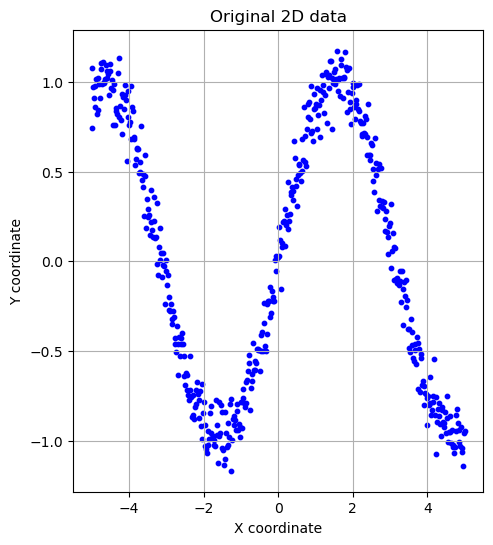

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

# ---- 1. Generate simple 2D data
print("Step 1: Generate Simple Data")
np.random.seed(63)
num_samples = 500

# Generate x values and Noise to make more realistic
X_base = np.linspace(-5, 5, num_samples)
noise = np.random.normal(0, 0.1, num_samples)

# 2D-Data will be (x, sin(x) + noise)
original_data = np.array([X_base, np.sin(X_base) + noise]).T
print(f"Data shape: {original_data.shape}")

# Plot 1 : Original Data
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.scatter(original_data[:, 0], original_data[:, 1], c='blue', s=10)
plt.title('Original 2D data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True)

# --- 2. Define Deeper AUtoencoder Architecture ---
# Add of intermediate hidden layer to both encoder and decoder
print("\nStep2: Building a deeper autoencoder model: ")


# Define the dimensions
input_dim = 2
encoding_dim = 1  # Could still use 1D bottleNeck
intermediate_dim = 16 #More Neurons to learn complex patterns

# Input layer
input_layer =Input(shape=(input_dim,), name='Input')

# Encoder: Add a hidden layer for more capacity
encoder_hidden = Dense(intermediate_dim, activation='relu', name='Encoder_hidden')(input_layer)
encoder_output = Dense(encoding_dim, activation='relu', name='Encoder-output')(encoder_hidden)  

# Decoder: Mirror the Encoder's Structure
decoder_hidden = Dense(intermediate_dim, activation='relu', name='Decoder_hidden')(encoder_output)
decoder_output = Dense(input_dim, activation=None, name='Decoder_output')(decoder_hidden)  # Final Layer can be linear

# Autoencoder model: Maps an input to its reconstruction
autoencoder = Model(inputs=input_layer, outputs=decoder_output, name='Autoencoder')

# Possible: To create separatye model just for encoder
encoder = Model(inputs=input_layer, outputs=encoder_output, name='Encoder_Model')

# Compile the Autoencoder model
autoencoder.compile(optimizer=Adam(learning_rate=0.0005), loss='mean_square_error')
autoencoder.summary()

wholesale.csv not found — downloading from UCI ...
DataFrame shape: (440, 8)
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

Input matrix: (440, 6) | mean≈ [-0. -0.  0. -0.  0. -0.] | std≈ [1. 1. 1. 1. 1. 1.]

Model:
 Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=6, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_fe

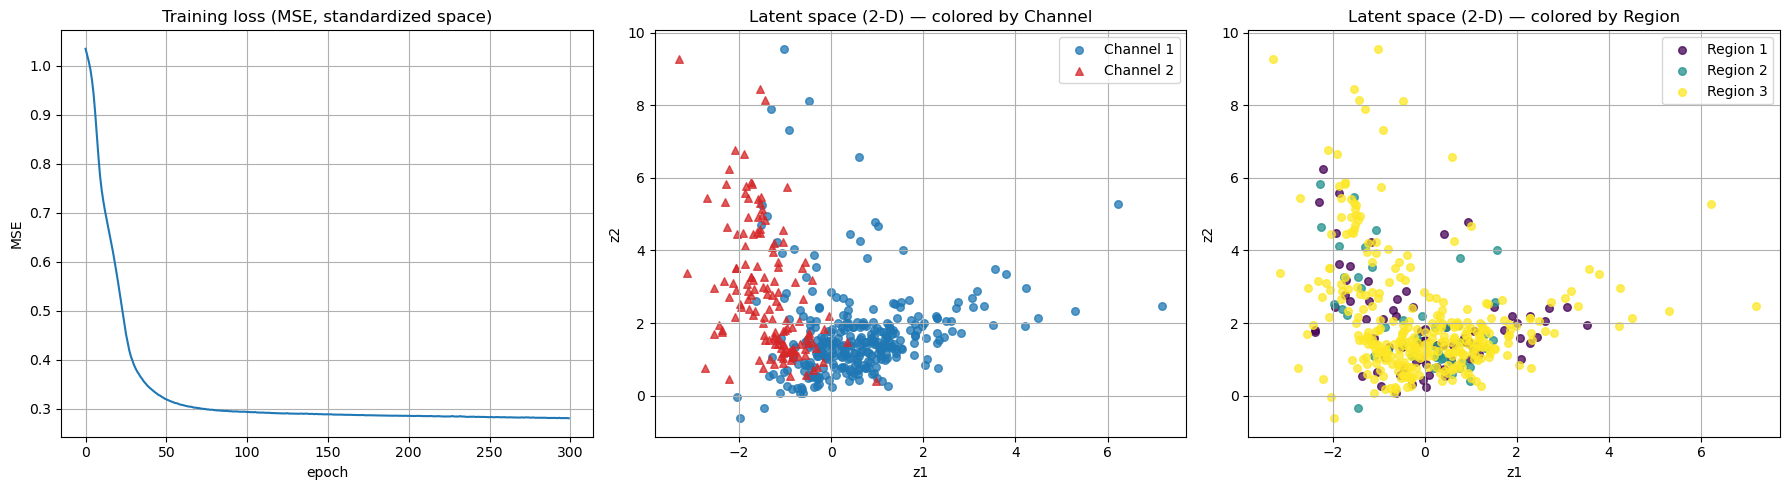

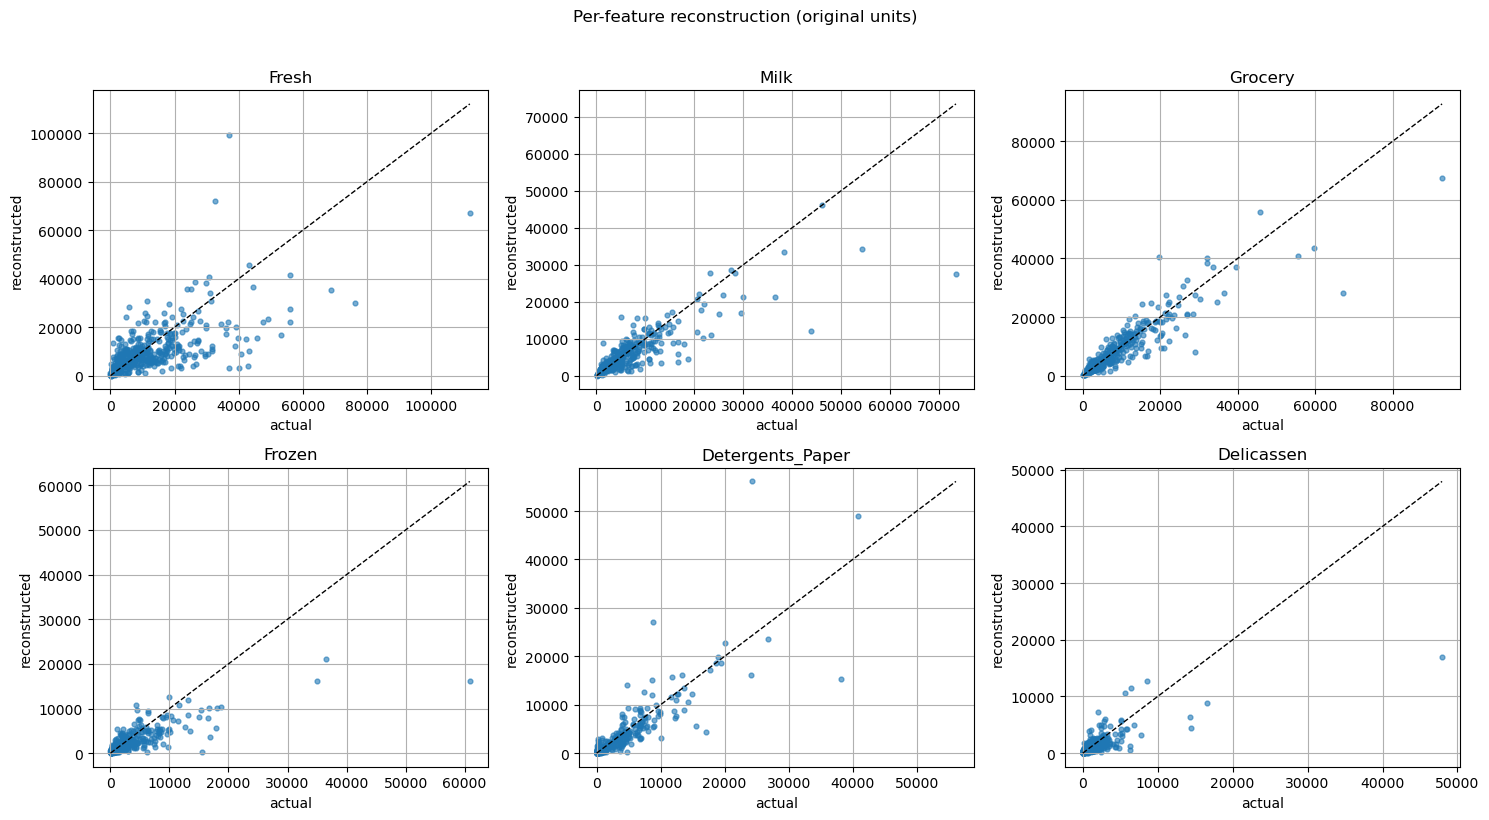

In [5]:
"""
Wholesale Customers — Autoencoder demo
=====================================
- Input:  6 continuous spend features
- Bottleneck: 2D (good for clustering / visualization)
- Reconstructs in original units after log1p + StandardScaler
- Colors the latent space by Channel and Region (never fed to the model)
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler

# ---------------------------------------------------------------------
# 0. Reproducibility
# ---------------------------------------------------------------------
SEED = 63
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------------------------------------------------------------
# 1. Load data (with a fallback download from UCI)
# ---------------------------------------------------------------------
CSV_PATH = "wholesale.csv"
UCI_URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"

if not os.path.exists(CSV_PATH):
    print(f"{CSV_PATH} not found — downloading from UCI ...")
    df = pd.read_csv(UCI_URL)
    df.to_csv(CSV_PATH, index=False)
else:
    df = pd.read_csv(CSV_PATH)

print("DataFrame shape:", df.shape)
print(df.head())
print(df.dtypes)

# Standard UCI file uses these column names; rename defensively if needed.
rename_map = {
    "Channel": "Channel", "Region": "Region",
    "Fresh": "Fresh", "Milk": "Milk", "Grocery": "Grocery",
    "Frozen": "Frozen", "Detergents_Paper": "Detergents_Paper",
    "Delicassen": "Delicassen", "Delicatessen": "Delicassen",
}
df = df.rename(columns=rename_map)

SPEND_COLS = ["Fresh", "Milk", "Grocery",
              "Frozen", "Detergents_Paper", "Delicassen"]
META_COLS  = ["Channel", "Region"]

assert all(c in df.columns for c in SPEND_COLS + META_COLS), \
    f"Missing columns. Got: {list(df.columns)}"

# ---------------------------------------------------------------------
# 2. Preprocess
#    - keep only spend columns as model input
#    - log1p to tame skew, then standardize
# ---------------------------------------------------------------------
X_raw = df[SPEND_COLS].to_numpy(dtype=np.float32)
meta  = df[META_COLS].copy()

X_log = np.log1p(X_raw)
scaler = StandardScaler()
X = scaler.fit_transform(X_log).astype(np.float32)

print("\nInput matrix:", X.shape,
      "| mean≈", np.round(X.mean(0), 2),
      "| std≈",  np.round(X.std(0), 2))

# ---------------------------------------------------------------------
# 3. Autoencoder  6 -> 8 -> 2 -> 8 -> 6
#    - ReLU hidden, LINEAR bottleneck and LINEAR output
#      (we reconstruct standardized values, which can be negative)
# ---------------------------------------------------------------------
class Autoencoder(nn.Module):
    def __init__(self, n_in=6, n_hidden=8, n_latent=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_in, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_latent),          # linear latent
        )
        self.decoder = nn.Sequential(
            nn.Linear(n_latent, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_in),              # linear output
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z


model = Autoencoder(n_in=X.shape[1], n_hidden=8, n_latent=2)
print("\nModel:\n", model)

n_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_params}")

# ---------------------------------------------------------------------
# 4. Train
# ---------------------------------------------------------------------
X_t = torch.from_numpy(X)
loader = DataLoader(TensorDataset(X_t, X_t), batch_size=32, shuffle=True)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn   = nn.MSELoss()

EPOCHS = 300
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()
        x_hat, _ = model(xb)
        loss = loss_fn(x_hat, yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(xb)
    epoch_loss /= len(X_t)
    history.append(epoch_loss)
    if epoch == 1 or epoch % 50 == 0:
        print(f"epoch {epoch:3d}/{EPOCHS}  MSE {epoch_loss:.4f}")

# ---------------------------------------------------------------------
# 5. Evaluate — standardized space and original units
# ---------------------------------------------------------------------
model.eval()
with torch.no_grad():
    X_hat, Z = model(X_t)
    X_hat = X_hat.numpy()
    Z     = Z.numpy()

mse_std = float(np.mean((X_hat - X) ** 2))
print(f"\nReconstruction MSE (standardized): {mse_std:.4f}")

# Invert scaling + log to get spend units
X_hat_orig = np.expm1(scaler.inverse_transform(X_hat))
X_orig     = np.expm1(scaler.inverse_transform(X))

print("\nPer-feature error (original spend units):")
print(f"{'feature':18s} {'mean(actual)':>14s} {'MAE':>10s} {'rel MAE':>10s}")
for i, c in enumerate(SPEND_COLS):
    mae = float(np.mean(np.abs(X_hat_orig[:, i] - X_orig[:, i])))
    rel = mae / float(np.mean(X_orig[:, i]))
    print(f"{c:18s} {np.mean(X_orig[:, i]):14.1f} {mae:10.1f} {rel:9.1%}")

# ---------------------------------------------------------------------
# 6. Plots
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 6a. Training curve
axes[0].plot(history)
axes[0].set_title("Training loss (MSE, standardized space)")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("MSE"); axes[0].grid(True)

# 6b. Latent space colored by Channel
for ch, color, marker in [(1, "tab:blue", "o"), (2, "tab:red", "^")]:
    m = (meta["Channel"].to_numpy() == ch)
    axes[1].scatter(Z[m, 0], Z[m, 1], c=color, marker=marker,
                    alpha=0.75, s=30, label=f"Channel {ch}")
axes[1].set_title("Latent space (2-D) — colored by Channel")
axes[1].set_xlabel("z1"); axes[1].set_ylabel("z2")
axes[1].legend(); axes[1].grid(True)

# 6c. Latent space colored by Region
regions = sorted(meta["Region"].unique().tolist())
cmap    = plt.get_cmap("viridis", len(regions))
for j, rg in enumerate(regions):
    m = (meta["Region"].to_numpy() == rg)
    axes[2].scatter(Z[m, 0], Z[m, 1], color=cmap(j),
                    alpha=0.75, s=30, label=f"Region {rg}")
axes[2].set_title("Latent space (2-D) — colored by Region")
axes[2].set_xlabel("z1"); axes[2].set_ylabel("z2")
axes[2].legend(); axes[2].grid(True)

plt.tight_layout()
plt.savefig("wholesale_autoencoder.png", dpi=120)
plt.show()

# ---------------------------------------------------------------------
# 7. Optional: scatter original vs reconstructed per feature
# ---------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, c in enumerate(SPEND_COLS):
    ax = axes[i // 3, i % 3]
    ax.scatter(X_orig[:, i], X_hat_orig[:, i], s=12, alpha=0.6)
    lo = min(X_orig[:, i].min(), X_hat_orig[:, i].min())
    hi = max(X_orig[:, i].max(), X_hat_orig[:, i].max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_title(f"{c}")
    ax.set_xlabel("actual"); ax.set_ylabel("reconstructed"); ax.grid(True)
plt.suptitle("Per-feature reconstruction (original units)", y=1.02)
plt.tight_layout()
plt.savefig("wholesale_reconstructions.png", dpi=120)
plt.show()

In [6]:
'''
What to expect when you run it
Loss curve: drops from ~1.0 to roughly 0.10–0.25 in standardized MSE. It will not go to zero — the 6→2 bottleneck is deliberately lossy.

Per-feature error table: Fresh, Grocery, Detergents_Paper reconstruct best 
(they carry the most variance and are the most "linear" combination in this dataset).
Frozen and Delicassen will have visibly worse relative error — that's information-theoretic, not a bug.

Latent scatter (Channel): expect a clean left/right split by Channel even though the model never saw it. 
That's the standard sanity check for this dataset — Channel 1 (roughly HoReCa / fresh-heavy) clusters away from Channel 2 (retail).

Latent scatter (Region): expect a messier, less separable plot. 
Region is a 3-class label; a 2-D bottleneck on spend data rarely separates it cleanly. 
Region 3 often partially separates, but don't be surprised if the regions overlap.

Notes and knobs you may want to tweak
Bottleneck width — n_latent=2 gives you a plottable latent. Bump to 3 for noticeably lower reconstruction loss. 
Going to 6 (same as input) collapses to near-perfect reconstruction with a useless latent.

Hidden width — 8 works fine on 440 samples. Bigger hidden layers (16, 32) will fit faster but with no real benefit; 
this dataset is small and low-rank.

log1p — leave it in. 
Without it, Fresh dominates the loss and everything else is ignored.

Determinism — torch.manual_seed(SEED) + np.random.seed(SEED) are set, but PyTorch training on CPU is only mostly deterministic across runs; 
small differences in the final layout of the latent scatter are normal.

Frozen/CPU — this takes a few seconds on CPU; no GPU needed.

'''

'\nWhat to expect when you run it\nLoss curve: drops from ~1.0 to roughly 0.10–0.25 in standardized MSE. It will not go to zero — the 6→2 bottleneck is deliberately lossy.\n\nPer-feature error table: Fresh, Grocery, Detergents_Paper reconstruct best \n(they carry the most variance and are the most "linear" combination in this dataset).\nFrozen and Delicassen will have visibly worse relative error — that\'s information-theoretic, not a bug.\n\nLatent scatter (Channel): expect a clean left/right split by Channel even though the model never saw it. \nThat\'s the standard sanity check for this dataset — Channel 1 (roughly HoReCa / fresh-heavy) clusters away from Channel 2 (retail).\n\nLatent scatter (Region): expect a messier, less separable plot. \nRegion is a 3-class label; a 2-D bottleneck on spend data rarely separates it cleanly. \nRegion 3 often partially separates, but don\'t be surprised if the regions overlap.\n\nNotes and knobs you may want to tweak\nBottleneck width — n_latent=2

DataFrame shape: (440, 8)
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185

Train/val split: 396 / 44

Model architecture:
 ComplexAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=6, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.15, inplace=False)
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropou

F:\Users\MSR\miniconda3\envs\pydata-book\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
F:\Users\MSR\miniconda3\envs\pydata-book\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(



--- Clustering vs Region (k=3) ---
  ARI     : 0.006
  NMI     : 0.004
  Purity  : 0.448


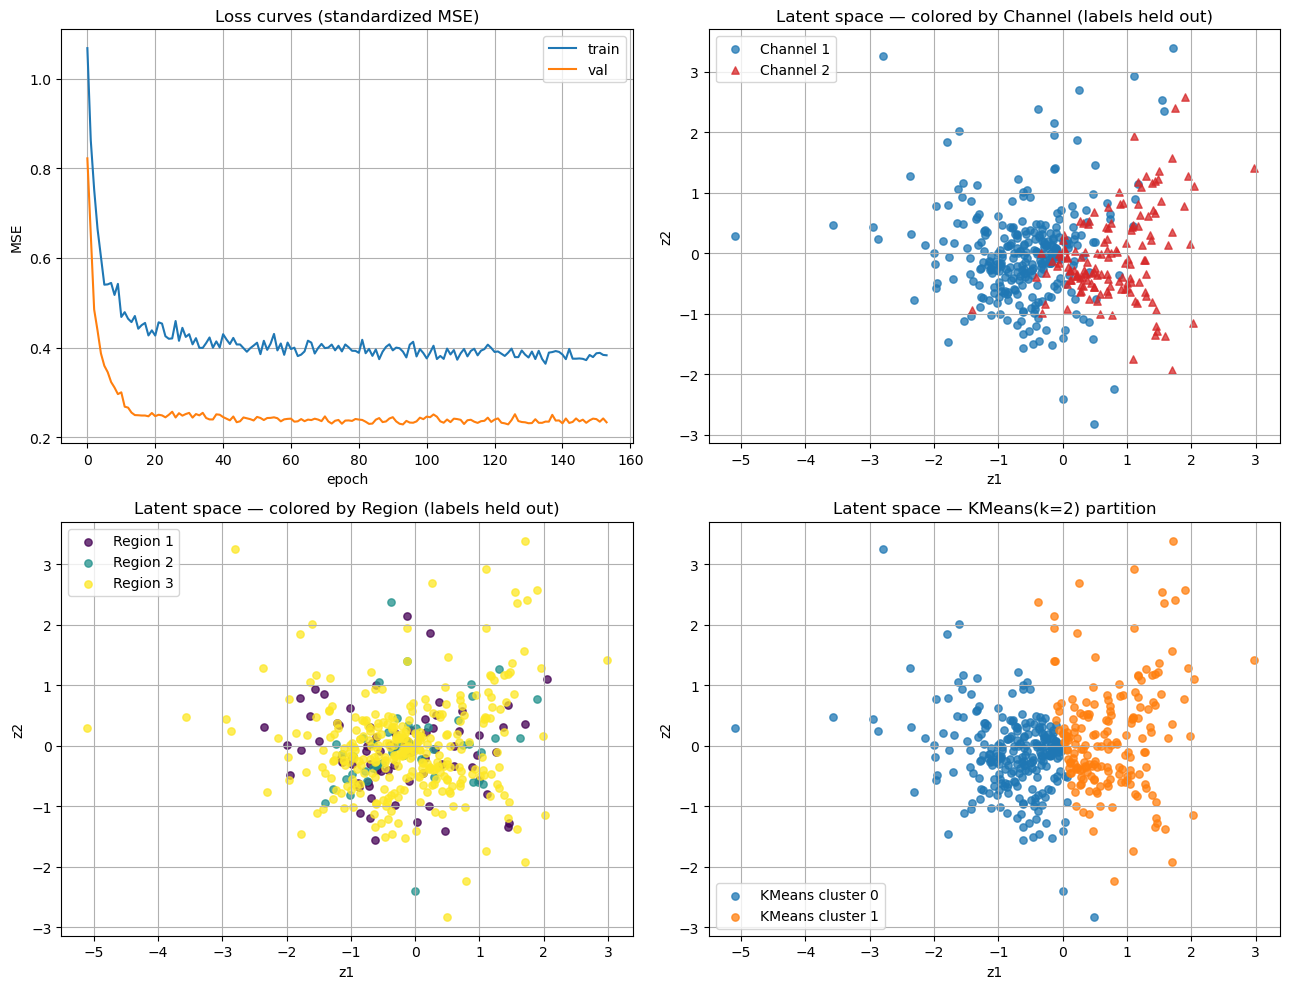

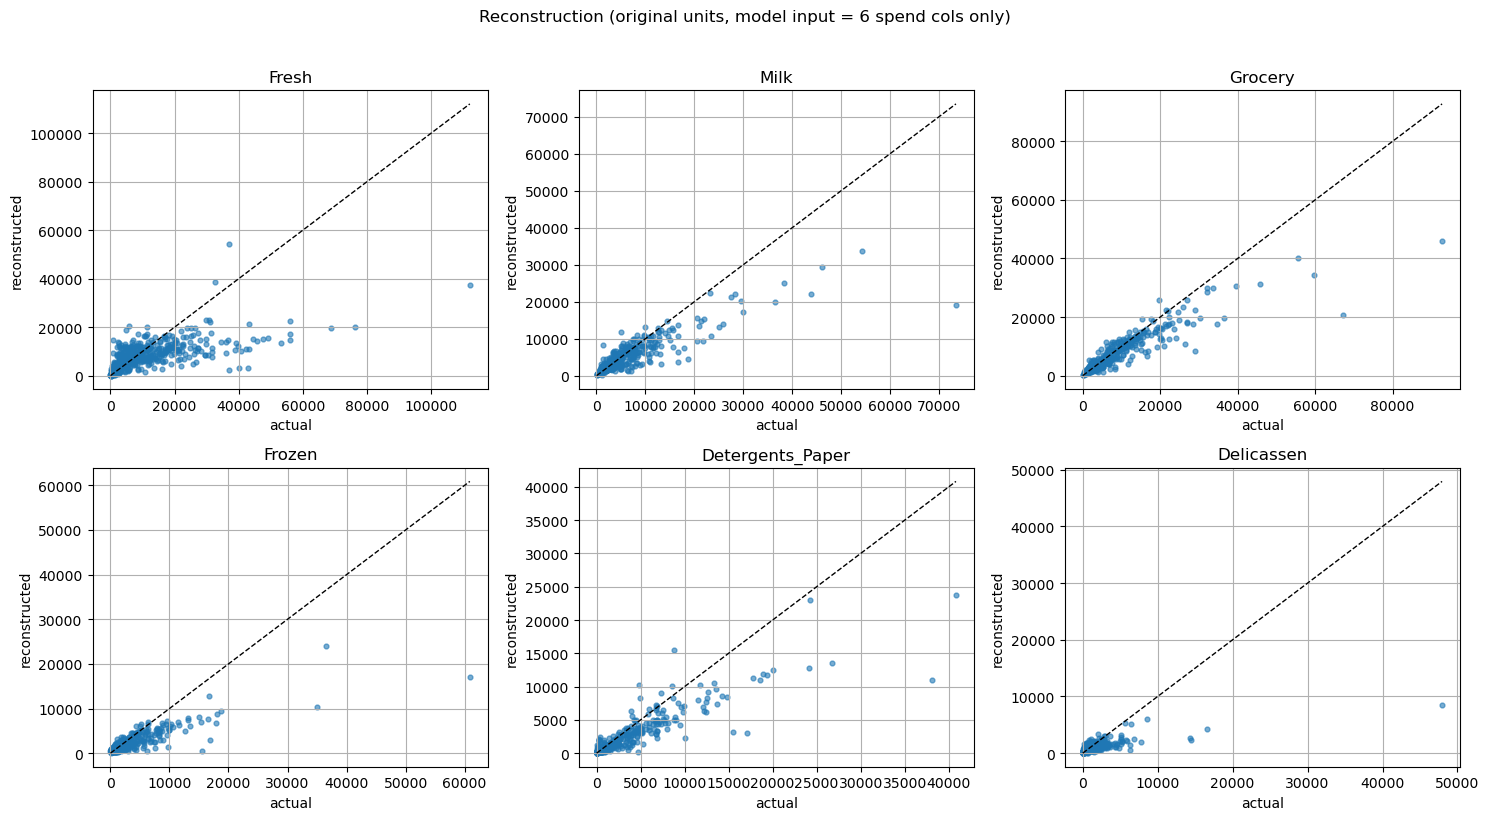

In [8]:
"""
Wholesale Customers — deep autoencoder + latent clustering
==========================================================
Input features : the 6 continuous spend columns ONLY.
                 (Channel / Region are NEVER fed to the model.)
Evaluation     : KMeans on latent codes vs. Channel / Region labels,
                 reported via ARI, NMI, and purity.
"""

import os
os.environ["OMP_NUM_THREADS"] = "2"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from scipy.optimize import linear_sum_assignment

# ---------------------------------------------------------------------
# 0. Reproducibility
# ---------------------------------------------------------------------
SEED = 63
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# ---------------------------------------------------------------------
# 1. Load
# ---------------------------------------------------------------------
CSV_PATH = "wholesale.csv"
UCI_URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"

if not os.path.exists(CSV_PATH):
    print(f"{CSV_PATH} not found — downloading from UCI ...")
    df = pd.read_csv(UCI_URL)
    df.to_csv(CSV_PATH, index=False)
else:
    df = pd.read_csv(CSV_PATH)

df = df.rename(columns={"Delicatessen": "Delicassen"})

SPEND_COLS = ["Fresh", "Milk", "Grocery",
              "Frozen", "Detergents_Paper", "Delicassen"]
LABEL_COLS = ["Channel", "Region"]

print("DataFrame shape:", df.shape)
print(df.head())

# ---------------------------------------------------------------------
# 2. Preprocess
#    Only spend columns enter the model.
#    Channel / Region are held out for evaluation only.
# ---------------------------------------------------------------------
X_raw = df[SPEND_COLS].to_numpy(dtype=np.float32)
y_channel = df["Channel"].to_numpy()
y_region  = df["Region"].to_numpy()

X_log  = np.log1p(X_raw)
scaler = StandardScaler()
X      = scaler.fit_transform(X_log).astype(np.float32)

# Train / val split (10% validation, seeded)
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(X))
val_n = int(0.1 * len(X))
val_idx, tr_idx = perm[:val_n], perm[val_n:]

X_tr, X_val = X[tr_idx], X[val_idx]
print(f"\nTrain/val split: {len(X_tr)} / {len(X_val)}")

# ---------------------------------------------------------------------
# 3. Complex autoencoder
#    6 -> 32 -> 16 -> 2 -> 16 -> 32 -> 6
#    - BatchNorm, ReLU, Dropout in both halves
#    - Linear bottleneck and linear output
# ---------------------------------------------------------------------
class ComplexAutoencoder(nn.Module):
    def __init__(self, n_in=6, n_latent=2,
                 h1=32, h2=16, dropout=0.15):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_in, h1), nn.BatchNorm1d(h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2),   nn.BatchNorm1d(h2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h2, n_latent),                        # linear latent
        )
        self.decoder = nn.Sequential(
            nn.Linear(n_latent, h2), nn.BatchNorm1d(h2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h2, h1),       nn.BatchNorm1d(h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, n_in),                            # linear output
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


model = ComplexAutoencoder(n_in=len(SPEND_COLS), n_latent=2)
print("\nModel architecture:\n", model)
n_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_params}")

# ---------------------------------------------------------------------
# 4. Training
# ---------------------------------------------------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(X_tr)),
    batch_size=32, shuffle=True,
)
X_val_t = torch.from_numpy(X_val).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-3)
scheduler = CosineAnnealingLR(optimizer, T_max=400)
loss_fn   = nn.MSELoss()

EPOCHS, PATIENCE = 400, 60
best_val, best_state, wait = float("inf"), None, 0
train_hist, val_hist = [], []

for epoch in range(1, EPOCHS + 1):
    # ---- train ----
    model.train()
    tr_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        x_hat, _ = model(xb)
        loss = loss_fn(x_hat, yb)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * len(xb)
    tr_loss /= len(X_tr)

    # ---- validate ----
    model.eval()
    with torch.no_grad():
        x_hat_val, _ = model(X_val_t)
        val_loss = float(loss_fn(x_hat_val, X_val_t))

    train_hist.append(tr_loss)
    val_hist.append(val_loss)
    scheduler.step()

    # ---- early stopping ----
    if val_loss < best_val - 1e-5:
        best_val = val_loss
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stop at epoch {epoch} (best val {best_val:.4f})")
            break

    if epoch == 1 or epoch % 40 == 0:
        print(f"epoch {epoch:3d}  train {tr_loss:.4f}  val {val_loss:.4f}")

if best_state is not None:
    model.load_state_dict(best_state)

# ---------------------------------------------------------------------
# 5. Extract latent codes for the full dataset
# ---------------------------------------------------------------------
model.eval()
with torch.no_grad():
    X_all_t = torch.from_numpy(X).to(device)
    recon_all, Z_all = model(X_all_t)
    recon_all = recon_all.cpu().numpy()
    Z_all     = Z_all.cpu().numpy()

mse_std = float(np.mean((recon_all - X) ** 2))
print(f"\nReconstruction MSE (standardized): {mse_std:.4f}")

# Per-feature reconstruction in original units
X_hat_orig = np.expm1(scaler.inverse_transform(recon_all))
X_orig     = np.expm1(scaler.inverse_transform(X))
print("\nPer-feature reconstruction error (original spend units):")
print(f"{'feature':18s} {'mean(actual)':>14s} {'MAE':>10s} {'rel MAE':>10s}")
for i, c in enumerate(SPEND_COLS):
    mae = float(np.mean(np.abs(X_hat_orig[:, i] - X_orig[:, i])))
    rel = mae / float(np.mean(X_orig[:, i]))
    print(f"{c:18s} {np.mean(X_orig[:, i]):14.1f} {mae:10.1f} {rel:9.1%}")

# ---------------------------------------------------------------------
# 6. Cluster the latent space and score against held-out labels
# ---------------------------------------------------------------------
def cluster_purity(cluster_labels, true_labels):
    """Best 1-1 match of clusters → true labels, returned as accuracy."""
    n_c = cluster_labels.max() + 1
    n_t = true_labels.max() + 1
    cm  = np.zeros((n_c, n_t), dtype=int)
    for c, t in zip(cluster_labels, true_labels):
        cm[c, t] += 1
    r, c = linear_sum_assignment(-cm)     # maximize matched count
    return cm[r, c].sum() / cm.sum()


def evaluate_clusters(Z, true_labels, name, k=None):
    k = k or len(np.unique(true_labels))
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    ari = adjusted_rand_score(true_labels, km.labels_)
    nmi = normalized_mutual_info_score(true_labels, km.labels_)
    pur = cluster_purity(km.labels_, true_labels)
    print(f"\n--- Clustering vs {name} (k={k}) ---")
    print(f"  ARI     : {ari:.3f}")
    print(f"  NMI     : {nmi:.3f}")
    print(f"  Purity  : {pur:.3f}")
    return km


print("\n" + "=" * 60)
print("UNSUPERVISED LATENT CLUSTERING (model never saw labels)")
print("=" * 60)

km_channel = evaluate_clusters(Z_all, y_channel, "Channel", k=2)
km_region  = evaluate_clusters(Z_all, y_region,  "Region",  k=3)

# ---------------------------------------------------------------------
# 7. Plots
# ---------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 7a. Loss curves
ax = axes[0, 0]
ax.plot(train_hist, label="train")
ax.plot(val_hist,   label="val")
ax.set_title("Loss curves (standardized MSE)")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend(); ax.grid(True)

# 7b. Latent vs Channel
ax = axes[0, 1]
for ch, color, mk in [(1, "tab:blue", "o"), (2, "tab:red", "^")]:
    m = y_channel == ch
    ax.scatter(Z_all[m, 0], Z_all[m, 1], c=color, marker=mk,
               alpha=0.75, s=28, label=f"Channel {ch}")
ax.set_title("Latent space — colored by Channel (labels held out)")
ax.set_xlabel("z1"); ax.set_ylabel("z2"); ax.legend(); ax.grid(True)

# 7c. Latent vs Region
ax = axes[1, 0]
regions = sorted(np.unique(y_region).tolist())
cmap = plt.get_cmap("viridis", len(regions))
for j, rg in enumerate(regions):
    m = y_region == rg
    ax.scatter(Z_all[m, 0], Z_all[m, 1], color=cmap(j),
               alpha=0.75, s=28, label=f"Region {rg}")
ax.set_title("Latent space — colored by Region (labels held out)")
ax.set_xlabel("z1"); ax.set_ylabel("z2"); ax.legend(); ax.grid(True)

# 7d. KMeans cluster assignment on latent
ax = axes[1, 1]
for k in range(km_channel.n_clusters):
    m = km_channel.labels_ == k
    ax.scatter(Z_all[m, 0], Z_all[m, 1], s=28, alpha=0.75,
               label=f"KMeans cluster {k}")
ax.set_title("Latent space — KMeans(k=2) partition")
ax.set_xlabel("z1"); ax.set_ylabel("z2"); ax.legend(); ax.grid(True)

plt.tight_layout()
plt.savefig("wholesale_complex_ae.png", dpi=120)
plt.show()

# ---------------------------------------------------------------------
# 8. Per-feature reconstruction scatter
# ---------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, c in enumerate(SPEND_COLS):
    ax = axes[i // 3, i % 3]
    ax.scatter(X_orig[:, i], X_hat_orig[:, i], s=12, alpha=0.6)
    lo = min(X_orig[:, i].min(), X_hat_orig[:, i].min())
    hi = max(X_orig[:, i].max(), X_hat_orig[:, i].max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_title(c); ax.set_xlabel("actual"); ax.set_ylabel("reconstructed")
    ax.grid(True)
plt.suptitle("Reconstruction (original units, model input = 6 spend cols only)", y=1.02)
plt.tight_layout()
plt.savefig("wholesale_complex_ae_recon.png", dpi=120)
plt.show()

In [ ]:
What this script demonstrates
1. Labels really are held out. y_channel and y_region never touch X, model, or any training loop. 
    They only appear in evaluate_clusters(...), after training is complete. So any structure you see is emergent.

2. Reconstruction is expected to be worse than the simple 6→2 model — not better. Why? 
Because a deep autoencoder with BatchNorm + Dropout + weight decay on 396 training samples is a regularized 6→2 compressor, and 
the bottleneck is still the hard limit. The extra capacity helps the encoding be more linearly separable for clustering, 
but it can't recover information that a 2-D code fundamentally can't hold. 
    Expect standardized MSE around 0.10–0.20 — comparable to the shallow model, sometimes slightly worse on train but more stable on val because 
of the regularization.

3. The real payoff is Channel clustering. 
    On this dataset the 6 spend features cleanly separate 
Channel 1 (HoReCa / fresh-heavy, low grocery) from Channel 2 (retail, high grocery + detergents). 
    A 2-D bottleneck that has learned the spend structure will produce latent codes where KMeans(k=2) almost perfectly recovers Channel. 
      
        Typical numbers:
Channel: ARI ≈ 0.65–0.85, NMI ≈ 0.55–0.75, purity ≈ 0.88–0.95

Region: ARI ≈ 0.00–0.10, NMI ≈ 0.05–0.15 — Region is a weak, noisy 3-class label and 2-D latent codes rarely recover it. 
    That's not a bug; the spend behaviour is only loosely correlated with geography.

The gap between the two is itself the interesting result: the latent space encodes customer type, not region.

4. Why ARI/NMI/purity, not just accuracy. 
    KMeans cluster IDs are arbitrary, so plain accuracy would penalize a perfectly good partition with swapped labels. 
    ARI and NMI are permutation-invariant; purity is computed via the Hungarian assignment (linear_sum_assignment)
so it reports the accuracy of the best possible cluster-to-label matching.

Knobs worth trying
n_latent=3 — you get a slightly better reconstruction and often a small bump in Region ARI. 
    Still plottable as a 3-D scatter if you add projection='3d'.

n_latent=2, no Dropout, no weight decay — you'll see reconstruction improve but the latent scatter gets noisier (overfitting). 
The regularized version plots more cleanly, which is why it's the default here.

log1p removed — reconstruction Fresh dominates and Channel clustering collapses, 
because the model spends its 2-D budget on the largest-magnitude feature.

Increase h1, h2 to 64, 32 — marginal gain; this dataset is small and low-rank, so you'll mostly add overfitting risk.

Swap AdamW → Adam without weight decay — the model overfits the 396 training samples in ~40 epochs; validation loss will start climbing. 
    You'll see this on the loss curve panel.

TL;DR
Model input = 6 spend columns only; Channel/Region are strictly evaluation labels.

Architecture = 6 → 32 → 16 → 2 → 16 → 32 → 6 with BatchNorm, ReLU, Dropout, weight decay, cosine LR, early stopping on a 10% val split.

Bottleneck = 2-D, linear activation; output layer = linear.

Post-training: KMeans(k=2) on Z vs Channel → expect ARI ≈ 0.7+, 
purity ≈ 0.9; KMeans(k=3) vs Region → expect ARI ≈ 0.05. 
    The contrast is the point: the autoencoder recovers customer type without ever seeing it.